> **Lösungsversion für Lehrkräfte.** Die Version für die Lernenden im Hauptordner wird daraus mit `python3 material/quelle/schuelerversion_erstellen.py` erzeugt: Code zwischen `# >>> LOESUNG` und `# <<< LOESUNG` wird entfernt, Zeilen mit `# | ` werden zum Platzhalter.

In [1]:
# Nur in der Lehrkraft-Version: Hilfsmodul aus dem übergeordneten Ordner finden
import sys
sys.path.insert(0, "..")

# 12 – Faltungsnetz (CNN): Bilder wie ein Bildverarbeitungssystem auswerten

**Lernsituation „KI-Sichtprüfstation“ · Doppelstunden 6 und 7**

**Ziele – am Ende können Sie …**
- Faltung und Pooling erklären und selbst in NumPy berechnen,
- ein CNN mit Keras aufbauen und seine Merkmalskarten deuten,
- ein Modell mit Konfusionsmatrix, Precision und Recall bewerten,
- eine Konfidenzschwelle für die Prüfstation festlegen,
- ein Modell für den Raspberry Pi exportieren.

| Teil | Doppelstunde | Inhalt |
|---|:--:|---|
| A | 6 | Faltung und Pooling verstehen und selbst programmieren, CNN aufbauen |
| B | 7 | Training, Merkmalskarten, Bewertung, Konfidenzschwelle, Export, Teilzielkontrolle 3 |

**So lesen Sie dieses Notebook**

| Kennzeichen | Bedeutung |
|---|---|
| **[Lesen]** | Grundlagen – lesen oder interaktiv ausprobieren |
| **[Aufgabe]** | Code ausführen, ergänzen oder selbst schreiben |
| **[Frage]** | Frage beantworten – schriftlich oder im Gespräch |
| **[Test]** | Teilzielkontrolle |
| **[Industrie]** | Bezug zur Fertigung |
| **[Raspberry Pi]** | Hinweis für den Raspberry Pi |

In [2]:
# Werkzeuge laden – diese Zelle einfach ausführen (Umschalt + Enter)
import numpy as np
import cv2
import matplotlib.pyplot as plt
import ki_hilfen as kh

ORDNER = kh.ORDNER          # Ordner mit Notebooks, Datensätzen und Modellen

import keras
from keras import layers

kh.setze_seed(42)

---
## Teil A – Faltung und Pooling (Doppelstunde 6)

### [Lesen] Wie ein Filter Kanten findet

In [3]:
kh.zeige_html("06_faltung.html")

### [Aufgabe A1] Faltung selbst programmieren
Schreiben Sie die Funktion `falte(bild, kernel)` für ein Graustufenbild und einen 3 × 3-Filter **ohne Rand** („valid“):
- Das Ergebnis ist 2 Pixel schmaler und 2 Pixel niedriger als das Bild.
- Für jede Position `(i, j)`: Ausschnitt `bild[i:i+3, j:j+3]` mit dem Filter malnehmen und alles zusammenzählen (`np.sum`).

In [4]:
def falte(bild, kernel):
    h, w = bild.shape
    ergebnis = np.zeros((h - 2, w - 2))
    # >>> LOESUNG
    # | # TODO: zwei Schleifen über i und j
    for i in range(h - 2):
        for j in range(w - 2):
            ergebnis[i, j] = np.sum(bild[i:i + 3, j:j + 3] * kernel)
    # <<< LOESUNG
    return ergebnis


probe = np.array([[0, 0, 1, 1],
                  [0, 0, 1, 1],
                  [0, 0, 1, 1]])
kante_senkrecht = np.array([[-1, 0, 1],
                            [-1, 0, 1],
                            [-1, 0, 1]])
print(falte(probe, kante_senkrecht))
kh.pruefe_gleich(falte(probe, kante_senkrecht), [[3, 3]], "falte(probe)")

[[3. 3.]]


True

Jetzt mit einem echten Foto und drei Filtern. Hell bedeutet: Hier passt das Muster des Filters.

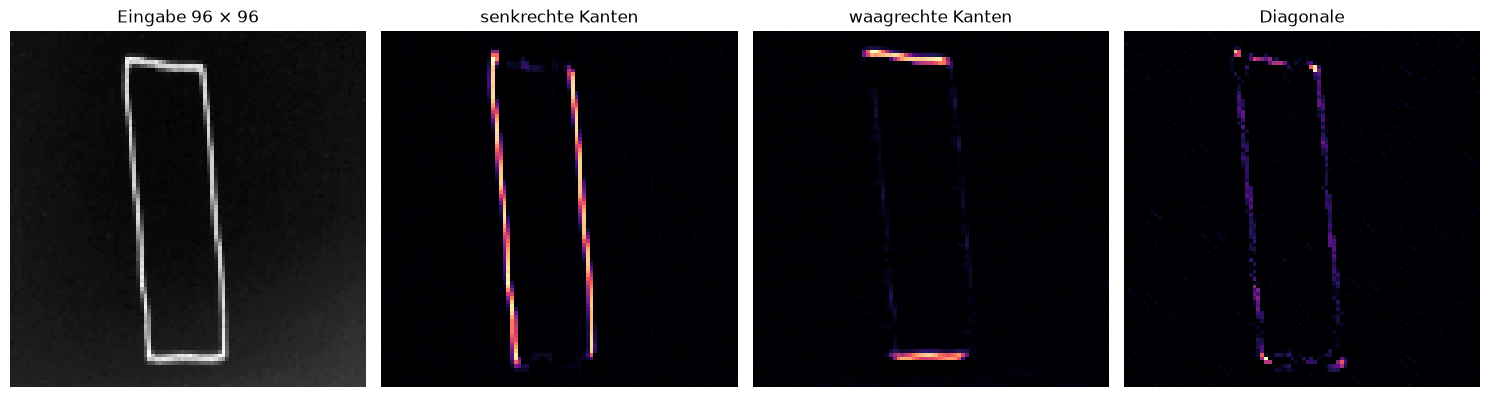

In [5]:
bild = cv2.imread(str(kh.bilddateien("dataset1/3")[0]))              # ein Quadrat
grau = kh.bild_vorbereiten(bild, 96, "grau")[..., 0] / 255
strich = 1 - grau                                                    # Strich hell, Papier dunkel

filter_liste = {
    "senkrechte Kanten": kante_senkrecht,
    "waagrechte Kanten": kante_senkrecht.T,
    "Diagonale": np.array([[2, -1, -1], [-1, 2, -1], [-1, -1, 2]]),
}
fig, ax = plt.subplots(1, 4, figsize=(15, 4))
ax[0].imshow(strich, cmap="gray"); ax[0].set_title("Eingabe 96 × 96")
for a, (name, k) in zip(ax[1:], filter_liste.items()):
    karte = np.maximum(falte(strich, k), 0)                         # ReLU: nur positive Werte
    a.imshow(karte, cmap="magma"); a.set_title(name)
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

### [Aufgabe A2] Max-Pooling selbst programmieren
`max_pool(karte)` zerlegt die Merkmalskarte in Blöcke von 2 × 2 Pixeln und behält aus jedem Block nur den **größten** Wert.

In [6]:
def max_pool(karte):
    h, w = karte.shape[0] // 2, karte.shape[1] // 2
    ergebnis = np.zeros((h, w))
    # >>> LOESUNG
    # | # TODO
    for i in range(h):
        for j in range(w):
            ergebnis[i, j] = karte[2 * i:2 * i + 2, 2 * j:2 * j + 2].max()
    # <<< LOESUNG
    return ergebnis


probe = np.array([[1, 2, 0, 0],
                  [3, 4, 0, 5],
                  [0, 0, 7, 0],
                  [1, 0, 0, 0]])
print(max_pool(probe))
kh.pruefe_gleich(max_pool(probe), [[4, 5], [1, 7]], "max_pool(probe)")

[[4. 5.]
 [1. 7.]]


True

### [Lesen] Ein CNN in Keras
In einem CNN werden die Filterwerte **nicht vorgegeben, sondern gelernt**. Jede `Conv2D`-Schicht hat viele Filter. Ihre Merkmalskarten werden gestapelt an die nächste Schicht weitergegeben. Je tiefer die Schicht, desto größer die Muster: erst Kanten, dann Ecken, dann ganze Formteile.

![CNN](../material/bilder/cnn.svg)

In [7]:
DATENSATZ = "dataset1"
GROESSE = 224              # alle Einstellungen wie im Original-Notebook 02b
FARBE = "rgb"
BATCH = 32
EPOCHEN = 300              # Obergrenze – EarlyStopping beendet meist nach 80 bis 120 Epochen
LERNRATE = 0.0003

X, y, klassen = kh.lade_datensatz(DATENSATZ, GROESSE, FARBE)
X_train, X_val, X_test, y_train, y_val, y_test = kh.teile_datensatz(X, y)
ANZAHL_KLASSEN = len(klassen)
print("Training:", len(X_train), " Validierung:", len(X_val), " Test:", len(X_test))

augmentierung = keras.Sequential([      # wie in Notebook 11 – nur beim Training aktiv
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.05),
])
train_ds = kh.als_tf_dataset(X_train, y_train, BATCH, mischen=True)
val_ds = kh.als_tf_dataset(X_val, y_val, BATCH)
test_ds = kh.als_tf_dataset(X_test, y_test, BATCH)

Aus Zwischenspeicher geladen: 176 Bilder
Training: 123  Validierung: 26  Test: 27


### [Aufgabe A3] Das CNN aufbauen
Ergänzen Sie das Modell nach der Tabelle. Der Anfang ist vorgegeben.

| Block | Schichten |
|---|---|
| Eingang | `keras.Input(shape=X_train.shape[1:])`, `layers.Rescaling(1/255)`, `augmentierung` *(vorgegeben)* |
| 1 | `layers.Conv2D(16, 3, padding="same", activation="relu")`, `layers.MaxPooling2D()` *(vorgegeben)* |
| 2 | Conv2D mit **32** Filtern, MaxPooling2D |
| 3 | Conv2D mit **64** Filtern, MaxPooling2D |
| 4 | Conv2D mit **128** Filtern, MaxPooling2D |
| 5 | Conv2D mit **16** Filtern, MaxPooling2D |
| Kopf | `layers.Flatten()`, `layers.Dense(256, activation="relu")`, `layers.Dropout(0.3)`, `layers.Dense(32, activation="relu")`, `layers.Dropout(0.3)`, `layers.Dense(ANZAHL_KLASSEN, activation="softmax")` |

In [8]:
modell = keras.Sequential([
    keras.Input(shape=X_train.shape[1:]),
    layers.Rescaling(1 / 255),
    augmentierung,
    layers.Conv2D(16, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    # >>> LOESUNG
    # | # TODO: Blöcke 2 bis 5 und den Kopf ergänzen
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(16, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(ANZAHL_KLASSEN, activation="softmax"),
    # <<< LOESUNG
])
modell.summary()

kh.pruefe_gleich(modell.output_shape, (None, ANZAHL_KLASSEN), "Ausgabe des Netzes")
kh.pruefe_gleich(sum(type(s).__name__ == "Conv2D" for s in modell.layers), 5, "Anzahl Faltungsschichten")

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 14, 14, 16)     │        18,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 7, 7, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         8,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 325,204 (1.24 MB)

 Trainable params: 325,204 (1.24 MB)

 Non-trainable params: 0 (0.00 B)

True

### [Frage]
1. Die zweite Faltungsschicht hat 4 640 Gewichte: 32 Filter × (3 × 3 × 16 + 1). Erklären Sie die Rechnung.
2. Nach fünfmal Pooling ist aus 224 × 224 eine Karte mit 7 × 7 geworden. Rechnen Sie nach.
3. Vergleichen Sie die Zahl der Gewichte mit dem FCNN aus Notebook 11 – obwohl das CNN 49-mal größere Bilder in Farbe verarbeitet.

---
## Teil B – Trainieren und bewerten (Doppelstunde 7)

[Raspberry Pi] Das CNN braucht viele Epochen: In den ersten Epochen bleibt die Genauigkeit bei etwa 25 % (Raten), danach steigt sie. EarlyStopping beendet das Training, wenn sich der Validierungsverlust 20 Epochen lang nicht verbessert – meist nach 80 bis 120 Epochen. Auf dem Raspberry Pi 5 dauert das ein bis zwei Stunden. Starten Sie das Training deshalb am Ende von Doppelstunde 6.

Training läuft – das dauert eine Weile ...
Trainiert: 135 Epochen · beste Epoche: 115 · Val-Genauigkeit dort: 1.0


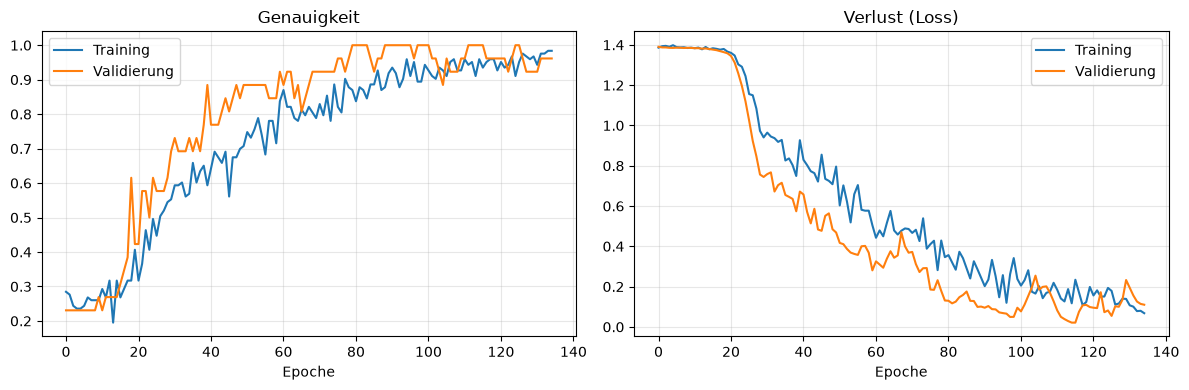

In [9]:
modell.compile(optimizer=keras.optimizers.Adam(LERNRATE),
               loss="sparse_categorical_crossentropy", metrics=["accuracy"])

bestes = kh.modellpfad("cnn_bestes.weights.h5")
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=20),
    keras.callbacks.ModelCheckpoint(bestes, monitor="val_loss",
                                    save_best_only=True, save_weights_only=True),
]
print("Training läuft – das dauert eine Weile ...")
verlauf = modell.fit(train_ds, validation_data=val_ds, epochs=EPOCHEN,
                     callbacks=callbacks, verbose=0)
modell.load_weights(bestes)
beste = int(np.argmin(verlauf.history["val_loss"]))
print("Trainiert:", len(verlauf.epoch), "Epochen · beste Epoche:", beste + 1,
      "· Val-Genauigkeit dort:", round(verlauf.history["val_accuracy"][beste], 3))
kh.zeige_lernkurven(verlauf)

### [Lesen] Was hat das CNN gelernt? Merkmalskarten
Für ein Testbild sehen Sie unten die Merkmalskarten der **ersten** Faltungsschicht – sortiert nach Stärke. Über jeder Karte steht der **gelernte 3 × 3-Filter**:
- rot = positives Gewicht, blau = negatives Gewicht,
- hell in der Karte = hier hat der Filter sein Muster gefunden.

Vergleichen Sie die gelernten Filter mit Ihren Kantenfiltern aus Aufgabe A1: Ein Filter mit rot links und blau rechts findet zum Beispiel senkrechte Kanten.

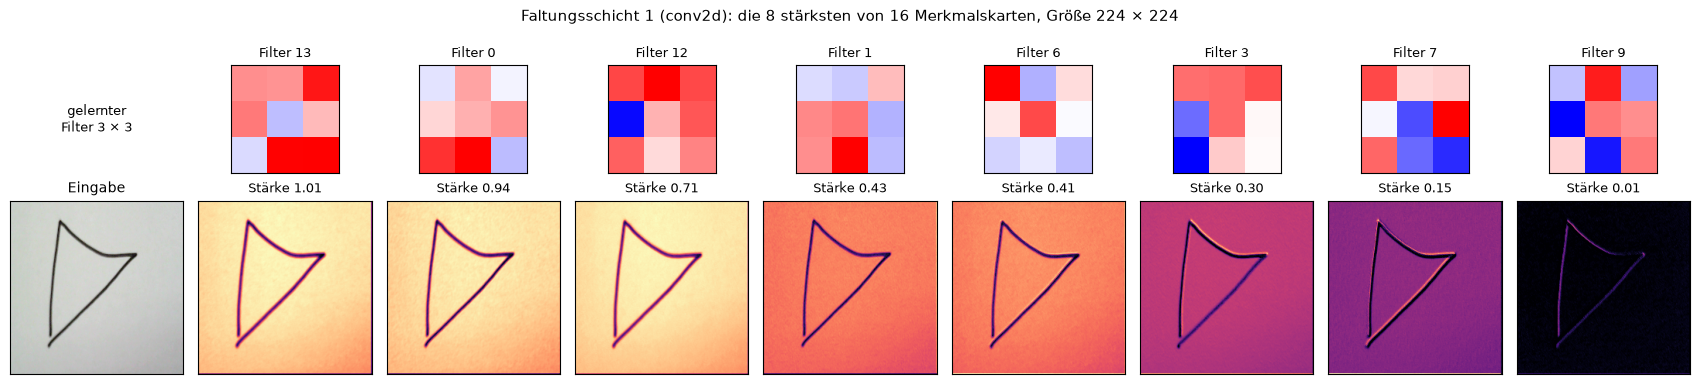

Oben: der gelernte Filter (rot = positives Gewicht, blau = negatives Gewicht).
Unten: seine Merkmalskarte – hell = hier hat der Filter sein Muster gefunden.


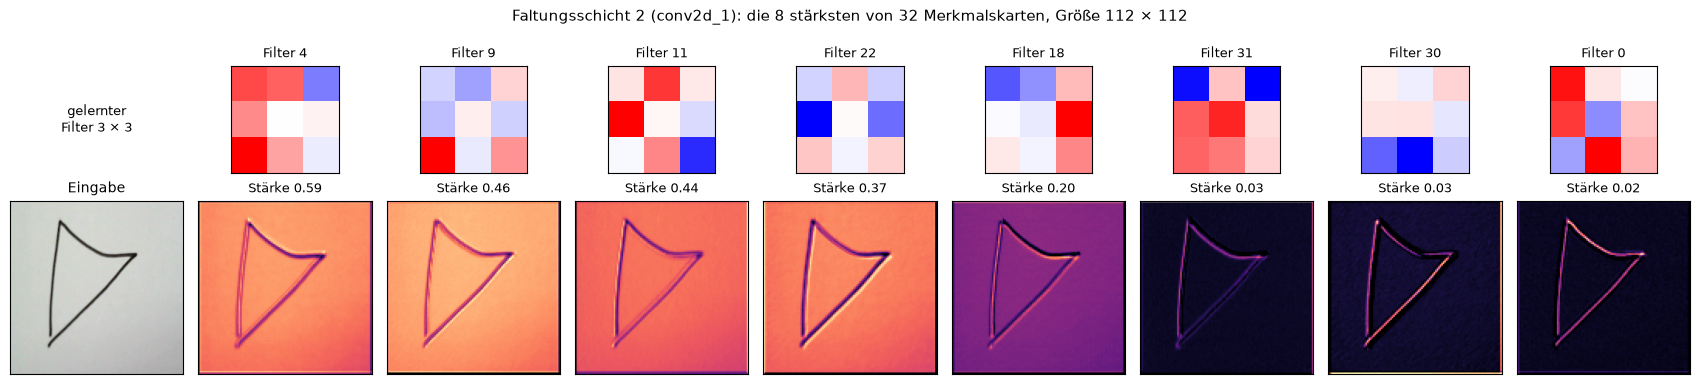

Oben: der gelernte Filter (rot = positives Gewicht, blau = negatives Gewicht).
Unten: seine Merkmalskarte – hell = hier hat der Filter sein Muster gefunden.


In [10]:
nr = 0                                       # Nummer des Testbildes – ändern Sie die Zahl!
kh.zeige_merkmalskarten(modell, X_test[nr], faltung_nr=1)
kh.zeige_merkmalskarten(modell, X_test[nr], faltung_nr=2)

### [Frage]
1. Welche Teile des Bildes werden in den Karten der ersten Schicht hell: das Symbol, die Papierkante, der Tisch?
2. Die Karten der zweiten Schicht sind nur noch halb so groß. Warum?
3. [Industrie] Viele Karten reagieren auch auf die Papierkante. Was bedeutet das für den Aufbau der Prüfstation (Hintergrund, Bildausschnitt)?

### [Lesen] Konfusionsmatrix

In [11]:
kh.zeige_html("07_bewertung.html")

Test-Genauigkeit CNN: 88.9 %


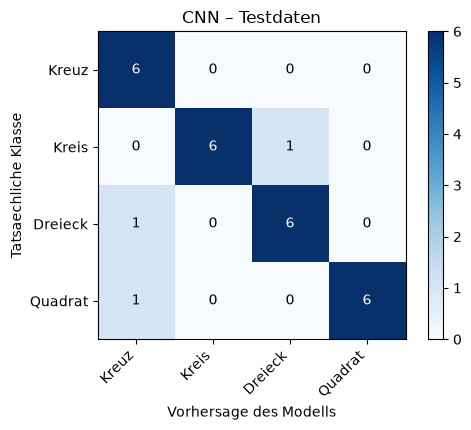

              precision    recall  f1-score   support

       Kreuz      0.750     1.000     0.857         6
       Kreis      1.000     0.857     0.923         7
     Dreieck      0.857     0.857     0.857         7
     Quadrat      1.000     0.857     0.923         7

    accuracy                          0.889        27
   macro avg      0.902     0.893     0.890        27
weighted avg      0.907     0.889     0.891        27



In [12]:
_, test_acc = modell.evaluate(test_ds, verbose=0)
print("Test-Genauigkeit CNN:", round(test_acc * 100, 1), "%")

wahrsch = modell.predict(X_test, verbose=0)
y_pred = wahrsch.argmax(axis=1)
cm = kh.zeige_konfusionsmatrix(y_test, y_pred, klassen, titel="CNN – Testdaten")

### [Aufgabe B1] Die häufigste Verwechslung finden
Finden Sie in der Konfusionsmatrix `cm` den größten Wert **außerhalb der Diagonale**. Hinweis: Kopie anlegen, mit `np.fill_diagonal(kopie, 0)` die Diagonale auf 0 setzen, dann `np.unravel_index(kopie.argmax(), kopie.shape)`.

In [13]:
# >>> LOESUNG
# | wahr_nr, erkannt_nr = 0, 0   # TODO
kopie = cm.copy()
np.fill_diagonal(kopie, 0)
wahr_nr, erkannt_nr = np.unravel_index(kopie.argmax(), kopie.shape)
# <<< LOESUNG

print(klassen[wahr_nr], "wurde", cm[wahr_nr, erkannt_nr], "Mal als", klassen[erkannt_nr], "erkannt.")
ohne_diagonale = cm - np.diag(np.diag(cm))
kh.pruefe_gleich(cm[wahr_nr, erkannt_nr], ohne_diagonale.max(), "größte Verwechslung")

Kreis wurde 1 Mal als Dreieck erkannt.


True

### [Industrie] Konfidenzschwelle
Die höchste Wahrscheinlichkeit nennen wir **Konfidenz**. Ist sie zu niedrig, soll die Station das Teil **nicht** selbst einsortieren, sondern zur Prüfung durch einen Menschen ausschleusen.

### [Aufgabe B2] Wirkung einer Schwelle berechnen
Berechnen Sie für die Testbilder:
- `konfidenz` – die höchste Wahrscheinlichkeit je Bild (`wahrsch.max(axis=1)`),
- `angenommen` – `True`, wenn `konfidenz >= schwelle`,
- `anteil_mensch` – Anteil der Bilder, die ein Mensch prüfen muss,
- `genauigkeit_automatisch` – Genauigkeit nur für die angenommenen Bilder.

In [14]:
schwelle = 0.80

# >>> LOESUNG
# | konfidenz = None                  # TODO
# | angenommen = None                 # TODO
# | anteil_mensch = None              # TODO
# | genauigkeit_automatisch = None    # TODO
konfidenz = wahrsch.max(axis=1)
angenommen = konfidenz >= schwelle
anteil_mensch = 1 - angenommen.mean()
genauigkeit_automatisch = (y_pred[angenommen] == y_test[angenommen]).mean()
# <<< LOESUNG

print("Schwelle", schwelle)
print("  zur Prüfung durch einen Menschen:", round(anteil_mensch * 100, 1), "%")
print("  Genauigkeit der automatischen Entscheidungen:", round(genauigkeit_automatisch * 100, 1), "%")
kh.pruefe_gleich(round(anteil_mensch, 4), round(float((wahrsch.max(axis=1) < schwelle).mean()), 4), "anteil_mensch")

Schwelle 0.8
  zur Prüfung durch einen Menschen: 0.0 %
  Genauigkeit der automatischen Entscheidungen: 88.9 %


True

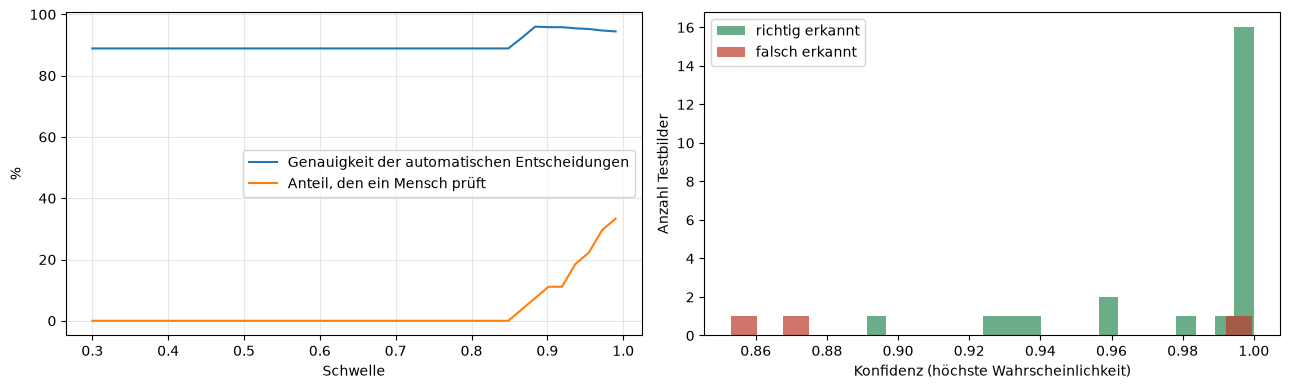

In [15]:
kh.zeige_schwellenwirkung(wahrsch, y_test)

### [Frage]
Welche Schwelle würden Sie für die Prüfstation wählen? Begründen Sie mit den Diagrammen (Abwägung zwischen einer Prüfung durch einen Menschen und einer Fehlentscheidung).

### Modell speichern und exportieren
Neben der `.keras`-Datei entsteht eine **TFLite**-Datei. TensorFlow Lite ist für kleine Rechner gebaut und auf dem Raspberry Pi bei der Vorhersage deutlich schneller.

In [16]:
kh.speichere_modell(modell, "cnn", klassen, GROESSE, FARBE,
                    test_genauigkeit=round(float(test_acc), 4), datensatz=DATENSATZ)

INFO:tensorflow:Assets written to: C:\Users\METZGE~1\AppData\Local\Temp\tmp0as428mv\assets


INFO:tensorflow:Assets written to: C:\Users\METZGE~1\AppData\Local\Temp\tmp0as428mv\assets


Saved artifact at 'C:\Users\METZGE~1\AppData\Local\Temp\tmp0as428mv'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  2501286092368: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2501286091168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2501286093568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2501286091648: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2501286094288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2501286091888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2501286095488: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2501286093808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2501286096448: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2501286095248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  25

{'name': 'cnn',
 'klassen': ['Kreuz', 'Kreis', 'Dreieck', 'Quadrat'],
 'groesse': 224,
 'farbe': 'rgb',
 'keras': 'cnn.keras',
 'erstellt': '2026-11-25 17:36',
 'test_genauigkeit': 0.8889,
 'datensatz': 'dataset1',
 'tflite': 'cnn.tflite'}

## [Test] Teilzielkontrolle 3

In [17]:
kh.zeige_html("tzk3_cnn_und_bewertung.html")

### Ausblick
Unser CNN musste alles selbst lernen – aus gut 1 000 Bildern. Große Netze wie **MobileNetV2** wurden mit über einer Million Bildern vortrainiert. In **Notebook 13** nutzen wir dieses Wissen (Transfer Learning).

In [18]:
kh.ram_aufraeumen()